# 01 · Preprocessing — Krishna 2021 Clear-Cell RCC (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate samples (Harmony), embed, remove detached islands, and check the
manifold's compartment structure. Krishna et al. profile advanced ccRCC (10x); the
malignant calls are `CD45- ccRCC CA9+` cells — CA9/CAIX is the canonical ccRCC marker
downstream of VHL-loss / HIF stabilisation, so the malignant compartment is a single
transcriptional identity rather than a set of published sub-subtypes. Every tunable
choice is *derived from this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Krishna2021_Kidney | category: Kidney


### Load malignant compartment
Krishna et al. annotate cell type directly; we take their `Malignant` calls (all
`CD45- ccRCC CA9+`).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('published malignant subtype(s):', adata.obs['cell_subtype'].unique().tolist())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Krishna2021_Kidney
Done.
full atlas: (167283, 15588)
malignant: (5715, 15588) | samples: 25
published malignant subtype(s): ['CD45- ccRCC CA9+']
expression: X max 7.33 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude and are dominated by one
patient (UT2). Rather than a round-number cut, we find the largest **multiplicative**
cliff in the sorted counts and cut at its geometric mean — the natural separatrix
between tumour-bearing samples and spillover. Here the cliff is exceptionally clean
(15.9× at 1609→101), so the rule keeps UT2's two well-sampled tumour regions and drops
the 23 samples of ≤101-cell spillover. **Caveat (reported):** the retained cells are
therefore two anatomical regions of a single patient, so batch integration below is
region-level within UT2 rather than cross-patient — the honest consequence of the
data-driven gap on this heavily patient-skewed compartment.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
print('kept samples:', list(keep), '| patient(s):', adata.obs['patient'].unique().tolist())

sorted per-sample counts: [3397 1609  101   85   72   66   63   45   42   34   25   25   19   19
   18   17   17   15   10    7    7    7    7    5    3]
largest gap: 1609 -> 101 (ratio 15.93)
derived threshold (geometric mean across the gap) = 403
kept 2/25 samples -> 5006 cells
kept samples: ['UT2_Center', 'UT2_Far'] | patient(s): ['UT2']


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing):
we take the strongest integration past which mixing plateaus. PC count (20) and UMAP
spread (1.3) follow the 10x precedents (Kürten/Sun/Bi, comparable cell counts).
**Determinism:** Harmony's KMeans is not seed-deterministic; a benign ±1–2% shift in
the mixing fractions or a handful of cells at the island step is within tolerance and
does not change any decision below.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# theta sweep: same-sample neighbour fraction (lower = better batch mixing)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1576 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1576
same-sample neighbour fraction | pre-Harmony 0.962 | sweep {2: 0.721, 5: 0.633, 10: 0.63}
selected theta = 10 (mixing plateaus; strongest integration without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop
any cell outside the main connected component — stripping physically detached specks
while keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('cells after island removal:', adata.shape[0])

removed 0 cells in 0 detached islands
cells after island removal: 5006


### Compartment structure + cycling check (data-driven)
Low-resolution Leiden (res=0.15) probes whether the manifold resolves into distinct
lobes (e.g. a cycling vs low-cycling split, as in the head-and-neck references). Here
it recovers a **single compartment**: the malignant manifold is one continuous ccRCC
state, and the publication's cell-cycle phase calls show it is low-cycling throughout
(~5% cycling), so there is no separate proliferation lobe to settle before Gate 1.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
if adata.obs['lobe'].nunique() == 1:
    adata.obs['compartment'] = 'ccRCC (CA9+)'
else:
    adata.obs['compartment'] = adata.obs['lobe']
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 5006}
cycling fraction per lobe: {'0': 0.05}
overall cycling fraction: 0.050
compartments: {'ccRCC (CA9+)': 5006}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-sample islands) on one continuous manifold. The read is
made on the regenerated embedding itself (not a scalar): UT2_Center and UT2_Far
intermix thoroughly across a single connected cloud, with zero detached islands after
the radius-graph step and a single Leiden compartment. **Gate 1 = GO.** (Caveat carried
forward: integration is region-level within patient UT2, per the threshold above.)

In [8]:
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples ({list(adata.obs["sample"].unique())}) share one continuous manifold')
print('detached islands removed above -> one connected component retained')
print('single Leiden compartment; cycling fraction low throughout')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

2 samples (['UT2_Center', 'UT2_Far']) share one continuous manifold
detached islands removed above -> one connected component retained
single Leiden compartment; cycling fraction low throughout
Gate 1: samples intermixed on one continuous manifold -> GO


### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5006, 14833)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 5006


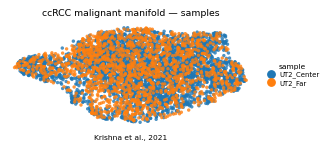

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match
# every other trajectory panel. Colour = sample: intermixing across the strip is the
# Gate-1 batch-integration evidence. The manifold's trajectory axis is horizontal in the
# raw embedding (corr(raw_umap_x, pseudotime) = -0.98, verified in 02), so the house
# orientation transform is identity + x-flip (X_umap_lin = [-raw_x, raw_y]); direction is
# immaterial for this categorical panel, so the raw embedding is shown here.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('ccRCC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Krishna et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])